In [1]:
%matplotlib inline
from pathlib import Path
import sys
cwd = Path.cwd().resolve()
repo_root = next((p for p in (cwd, *cwd.parents)
                  if (p / 'application_mnist' / 'data' / 'pipeline.py').exists()), None)
if repo_root is None:
    raise FileNotFoundError('Open the repository root in VS Code or set repo_root manually')
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from application_mnist.revision.model_io import load_experiment, label_name
from application_mnist.revision.reasons import sufficient_reasons, min_disagreement_reasons, term_text
from application_mnist.revision.revise import (apply_minimal_weakening, compare_predictions, export_revision, load_revision)
from application_mnist.revision.plotting import plot_instance_reason, plot_reasons_grid

from application_mnist.revision.global_pi_overview import (
    enumerate_global_prime_implicants,
    prepare_global_pi_overview,
    list_global_pi_reasons,
    plot_global_pi_overview,
)
from application_mnist.revision.global_pi_overview import (
    plot_single_global_pi_reason
)

print('Repository root:', repo_root)

Repository root: C:\Users\sofia\OneDrive\Desktop\Research\Code\ClassifierRevisionHumanFeedback


In [2]:
EXPERIMENT_NAME = '3_vs_8_g7_t20_seed42'
OUTPUT_DIR = (repo_root / 'application_mnist' / 'decision_tree' / 'outputs' / EXPERIMENT_NAME)

# OUTPUT_DIR = Path(r'C:\Users\sofia\OneDrive\Desktop\Research\Code\ClassifierRevisionHumanFeedback\application_mnist\decision_tree\outputs\3_vs_8_g7_t20_seed42')

ex = load_experiment(OUTPUT_DIR, max_nodes=150_000)
bdd, root, data = ex.bdd, ex.root, ex.data
print('Model output:', ex.output_dir)
print('Prepared dataset:', ex.dataset_path)
print('Task:', data['metadata']['task_name'])
print('All features:', len(ex.feature_names))
print('Features used by the exact classifier:', len(bdd.support(root)))
print('Reachable SDD nodes:', bdd.reachable_nodes(root))
print('Positive DNF leaf-path terms (not necessarily prime):', len(ex.positive_dnf.terms))
for name in ('train', 'val'):
    predicted = bdd.evaluate_batch(root, data[f'{name}_features'])
    print(f'{name}: {len(predicted)} examples; model accuracy {np.mean(predicted == data[f"{name}_labels"]):.3f}')


Model output:

 C:\Users\sofia\OneDrive\Desktop\Research\Code\ClassifierRevisionHumanFeedback\application_mnist\decision_tree\outputs\3_vs_8_g7_t20_seed42
Prepared dataset: C:\Users\sofia\OneDrive\Desktop\Research\Code\ClassifierRevisionHumanFeedback\application_mnist\data\processed\3_vs_8_g7_t20_seed42.npz
Task: 3_vs_8
All features: 49
Features used by the exact classifier: 9
Reachable SDD nodes: 46
Positive DNF leaf-path terms (not necessarily prime): 22
train: 1600 examples; model accuracy 0.922
val: 400 examples; model accuracy 0.907


## PI VISUALIZATION

In [3]:
pi_pos = enumerate_global_prime_implicants(
    bdd, root, class_label=1,
    method='auto', exact_nvars_limit=20,
    max_models=10000, max_reasons=500, max_seconds=60,
)
pi_neg = enumerate_global_prime_implicants(
    bdd, root, class_label=0,
    method='auto', exact_nvars_limit=20,
    max_models=10000, max_reasons=500, max_seconds=60,
)

print('Complete positive PIs?', pi_pos.complete)
print('Complete negative PIs?', pi_neg.complete)

PI(Delta): 23 reasons; method=models; SDD variables=21; complete=False
Partial: elapsed-time limit reached
PI(not Delta): 36 reasons; method=models; SDD variables=21; complete=False
Partial: rgr per-model search truncated: search: PipelineTimeout: deadline exceeded (ablation=full)
Complete positive PIs? False
Complete negative PIs? False


In [4]:
GLOBAL_SPLIT = 'train'
global_pos = prepare_global_pi_overview(
    data, bdd, root, split=GLOBAL_SPLIT, class_label=1, pi_result=pi_pos
)
global_neg = prepare_global_pi_overview(
    data, bdd, root, split=GLOBAL_SPLIT, class_label=0, pi_result=pi_neg
)

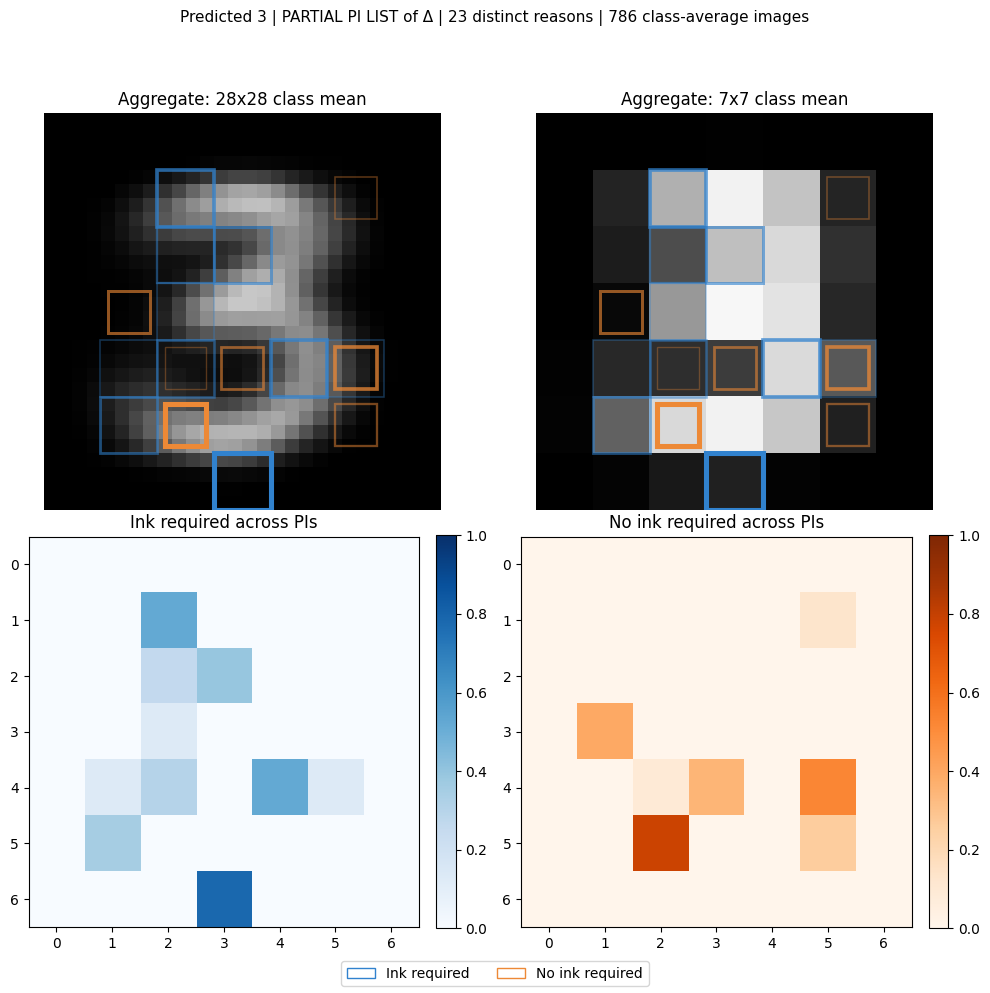

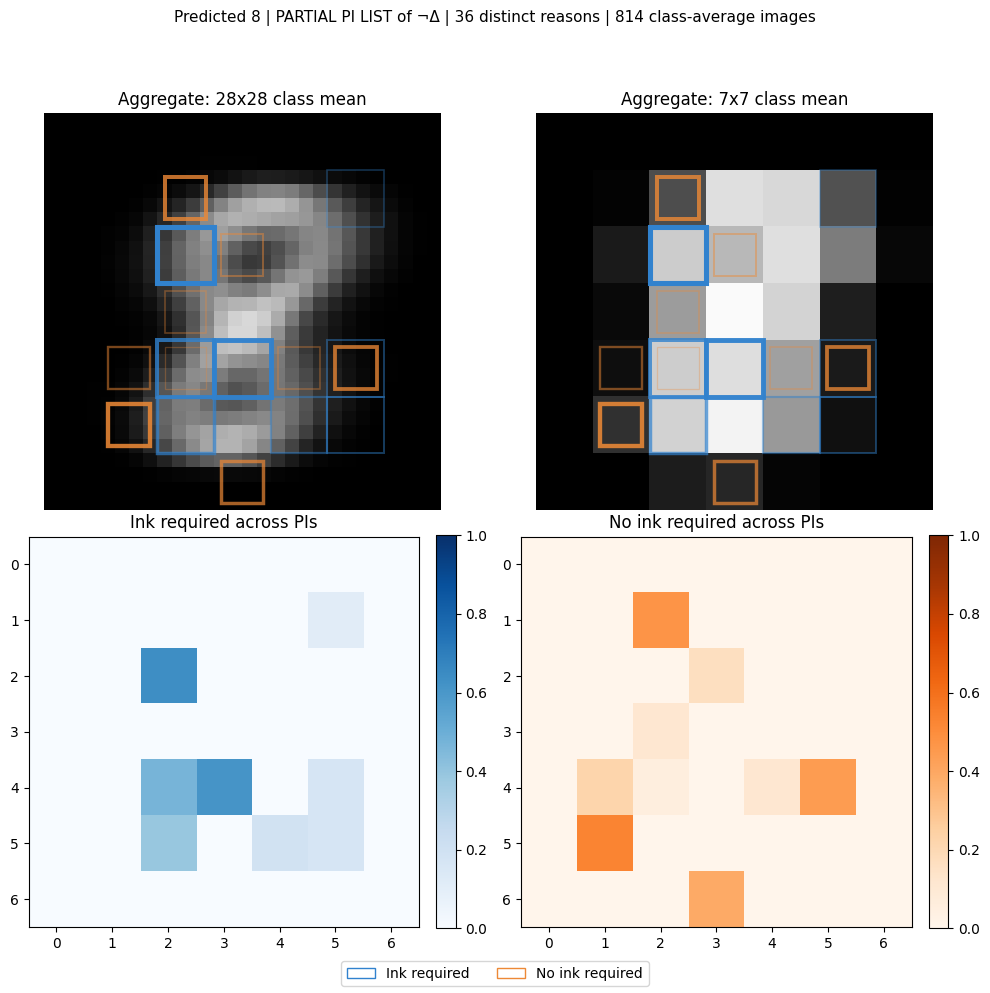

In [5]:
fig = plot_global_pi_overview(global_pos, data)
plt.show()
fig = plot_global_pi_overview(global_neg, data)
plt.show()

PI(Delta): 23 distinct reasons - PARTIAL
Partial: elapsed-time limit reached
  0 | len= 2 | ¬ink_r4_c2 ∧ ¬ink_r4_c3
  1 | len= 2 | ¬ink_r4_c2 ∧ ink_r5_c1
  2 | len= 5 | ink_r1_c2 ∧ ink_r2_c3 ∧ ¬ink_r3_c1 ∧ ¬ink_r4_c3 ∧ ink_r4_c5
  3 | len= 5 | ink_r2_c2 ∧ ink_r4_c2 ∧ ¬ink_r4_c5 ∧ ¬ink_r5_c2 ∧ ink_r6_c3
  4 | len= 5 | ink_r2_c2 ∧ ¬ink_r4_c3 ∧ ¬ink_r4_c5 ∧ ¬ink_r5_c2 ∧ ink_r6_c3
... plus 18 more (top_k=None to list all)
PI(not Delta): 36 distinct reasons - PARTIAL
Partial: rgr per-model search truncated: search: PipelineTimeout: deadline exceeded (ablation=full)
  0 | len= 4 | ¬ink_r1_c2 ∧ ink_r2_c2 ∧ ink_r4_c2 ∧ ink_r4_c5
  1 | len= 4 | ¬ink_r1_c2 ∧ ink_r2_c2 ∧ ink_r4_c2 ∧ ink_r5_c2
  2 | len= 4 | ¬ink_r1_c2 ∧ ink_r2_c2 ∧ ink_r4_c2 ∧ ¬ink_r6_c3
  3 | len= 4 | ink_r2_c2 ∧ ¬ink_r2_c3 ∧ ink_r4_c2 ∧ ink_r4_c5
  4 | len= 4 | ink_r2_c2 ∧ ¬ink_r2_c3 ∧ ink_r4_c2 ∧ ink_r5_c2
... plus 31 more (top_k=None to list all)
Selected prime implicant:
ink_r2_c2 ∧ ¬ink_r2_c3 ∧ ink_r4_c2 ∧ ink_r5_c2


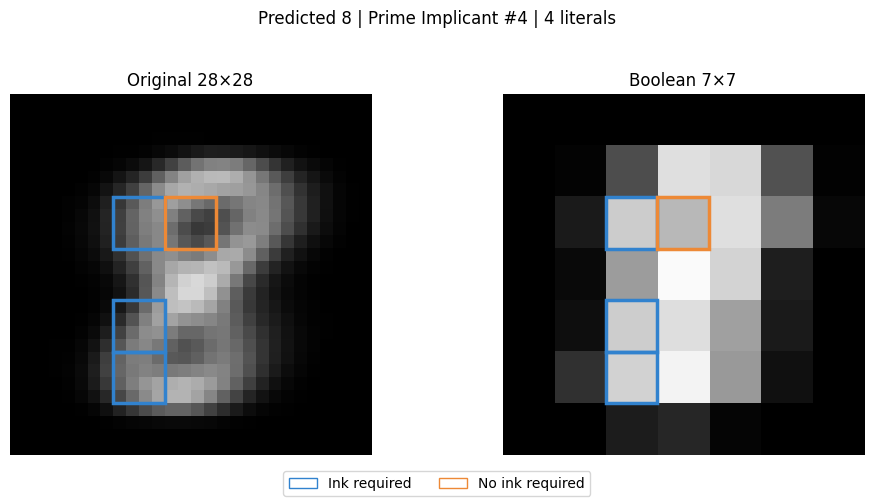

In [12]:


list_global_pi_reasons(global_pos, ex.feature_names, top_k=5)
list_global_pi_reasons(global_neg, ex.feature_names, top_k=5)

GLOBAL_CLASS = 0         # 1 = Δ, 0 = ¬Δ
GLOBAL_REASON_INDEX = 4

chosen_summary = global_pos if GLOBAL_CLASS == 1 else global_neg

selected_reason = chosen_summary["reasons"][GLOBAL_REASON_INDEX]

print("Selected prime implicant:")
print(term_text(selected_reason, ex.feature_names))

fig = plot_single_global_pi_reason(
    chosen_summary,
    data,
    reason_index=GLOBAL_REASON_INDEX,
)

plt.show()

## EXAMPLE IMAGE

In [13]:
SPLIT = "val"  # "train", "val", or "test"

X = data[f"{SPLIT}_features"]
y = data[f"{SPLIT}_labels"]
y_hat = bdd.evaluate_batch(root, X)


false_negatives = np.flatnonzero((y == 1) & (y_hat == 0))
false_positives = np.flatnonzero((y == 0) & (y_hat == 1))
errors = np.flatnonzero(y != y_hat)

print(f"Split: {SPLIT}")
print(f"Total examples: {len(y)}")
print(f"Incorrectly classified: {len(errors)} ({len(errors)/len(y):.2%})")

print(f"\nFalse negatives ({len(false_negatives)})")
print("Actual: -, Predicted: +")
print(false_negatives.tolist())

print(f"\nFalse positives ({len(false_positives)})")
print("Actual: +, Predicted: -")
print(false_positives.tolist())

Split: val
Total examples: 400
Incorrectly classified: 37 (9.25%)

False negatives (29)
Actual: -, Predicted: +
[3, 17, 32, 34, 71, 85, 102, 132, 143, 147, 155, 173, 186, 212, 222, 228, 231, 232, 265, 312, 332, 337, 347, 354, 363, 365, 369, 378, 379]

False positives (8)
Actual: +, Predicted: -
[9, 57, 79, 154, 157, 213, 246, 338]


Example: val 9
Ground truth: 8 , Model prediction: 3
Correctly classified? False


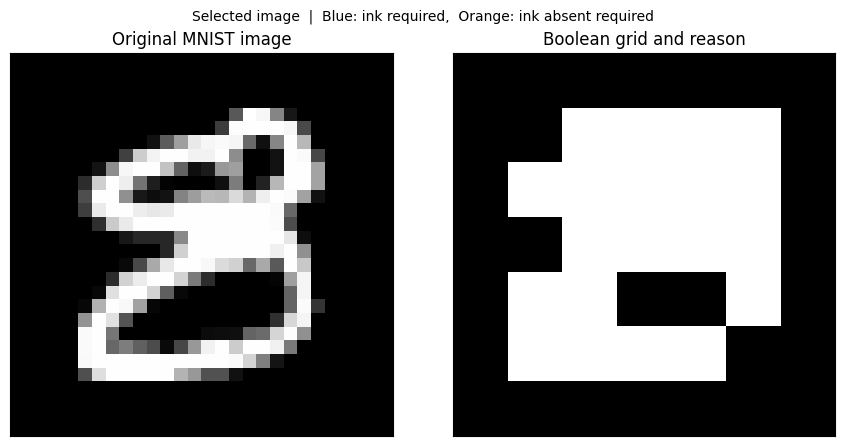

Instance: val[9]
Full Boolean representation:
¬ink_r0_c0 ∧ ¬ink_r0_c1 ∧ ¬ink_r0_c2 ∧ ¬ink_r0_c3 ∧ ¬ink_r0_c4 ∧ ¬ink_r0_c5 ∧ ¬ink_r0_c6 ∧ ¬ink_r1_c0 ∧ ¬ink_r1_c1 ∧ ink_r1_c2 ∧ ink_r1_c3 ∧ ink_r1_c4 ∧ ink_r1_c5 ∧ ¬ink_r1_c6 ∧ ¬ink_r2_c0 ∧ ink_r2_c1 ∧ ink_r2_c2 ∧ ink_r2_c3 ∧ ink_r2_c4 ∧ ink_r2_c5 ... (+29 more)


In [21]:

EXAMPLE_INDEX = 9  # None = first false negative, else first other mistake, else 0

if EXAMPLE_INDEX is None:
    EXAMPLE_INDEX = int(false_negatives[0] if len(false_negatives) else
                        errors[0] if len(errors) else 0)
instance = X[EXAMPLE_INDEX]
actual = int(y[EXAMPLE_INDEX])
predicted = int(y_hat[EXAMPLE_INDEX])
print('Example:', SPLIT, EXAMPLE_INDEX)
print('Ground truth:', label_name(data, actual), ', Model prediction:', label_name(data, predicted))
print('Correctly classified?' , actual == predicted)
fig = plot_instance_reason(data, split=SPLIT, index=EXAMPLE_INDEX, title='Selected image')
plt.show()

instance_term = tuple(
    (i, int(value))
    for i, value in enumerate(instance)
)

print(f"Instance: {SPLIT}[{EXAMPLE_INDEX}]")
print("Full Boolean representation:")
print(term_text(instance_term, ex.feature_names))

### PRIME IMPLICANTS


Predicted class: 3
Reasons found: 3 | Complete: True
Entailment queries: 91 | Complete
 0: 5 literals | ink_r1_c2 ∧ ink_r2_c3 ∧ ¬ink_r3_c1 ∧ ¬ink_r4_c3 ∧ ink_r4_c5
 1: 6 literals | ink_r1_c2 ∧ ink_r2_c3 ∧ ¬ink_r3_c1 ∧ ink_r4_c2 ∧ ink_r4_c5 ∧ ¬ink_r5_c5
 2: 6 literals | ink_r1_c2 ∧ ink_r2_c3 ∧ ¬ink_r3_c1 ∧ ink_r4_c5 ∧ ink_r5_c1 ∧ ¬ink_r5_c5


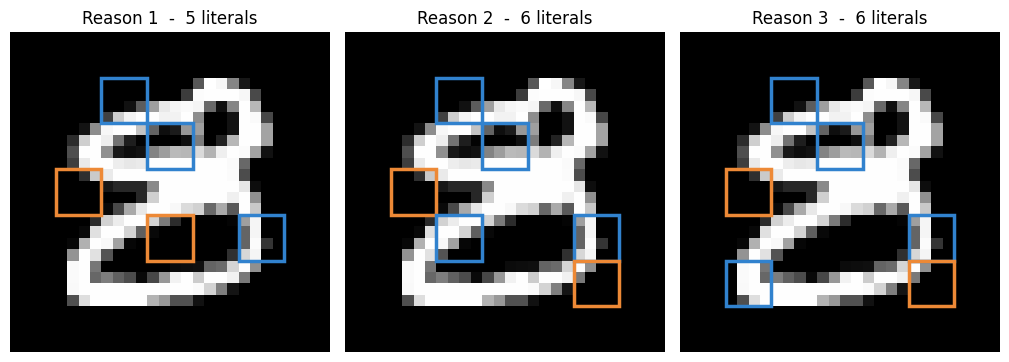

In [17]:
MAX_REASONS = 20
MAX_REASON_QUERIES = 600
reasons_now = sufficient_reasons(bdd, root, instance,
                                 max_reasons=MAX_REASONS,
                                 max_queries=MAX_REASON_QUERIES)
print('Predicted class:', label_name(data, reasons_now.predicted_label))
print('Reasons found:', len(reasons_now.reasons), '| Complete:', reasons_now.complete)
print('Entailment queries:', reasons_now.queries, '|', reasons_now.message)
for i, r in enumerate(reasons_now.reasons):
    print(f'{i:2}: {len(r)} literals | {term_text(r, ex.feature_names)}')
fig = plot_reasons_grid(data, split=SPLIT, index=EXAMPLE_INDEX,
                        reasons=reasons_now.reasons, max_show=5)
if fig is not None: plt.show()

### INSPECTING ONE REASON



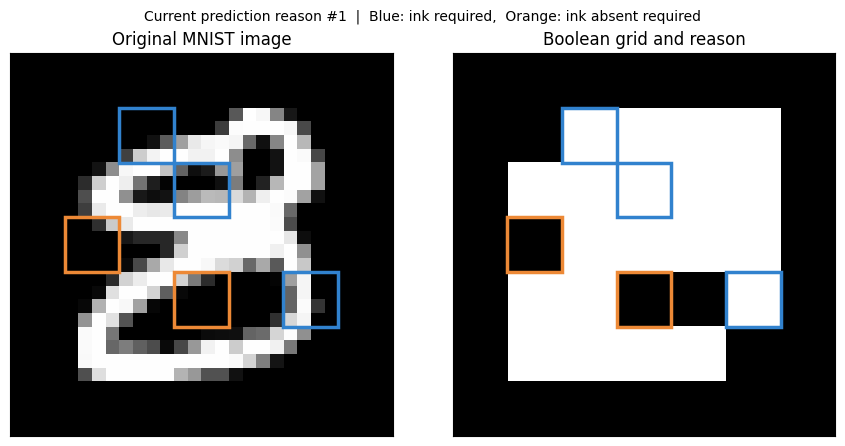

In [18]:
REASON_INDEX = 0
if reasons_now.reasons:
    selected_current_reason = reasons_now.reasons[REASON_INDEX]
    fig = plot_instance_reason(data, split=SPLIT, index=EXAMPLE_INDEX,
                               term=selected_current_reason,
                               title=f'Current prediction reason #{REASON_INDEX + 1}')
    plt.show()

## REVISION


In [19]:
MAX_NEAREST_MODELS = 30
MAX_CANDIDATE_REASONS = 30
MAX_QUERIES_PER_NEAREST_MODEL = 600

candidates = None
if predicted != actual:
    candidates = min_disagreement_reasons(
        bdd, root, instance, desired_label=actual,
        max_models=MAX_NEAREST_MODELS,
        max_reasons=MAX_CANDIDATE_REASONS,
        max_queries_per_model=MAX_QUERIES_PER_NEAREST_MODEL
    )
    print('Requested change:', label_name(data, predicted), '->', label_name(data, actual))
    print('Exact minimum disagreement distance:', candidates.nearest_distance)
    print('Nearest accepted models processed:', candidates.nearest_models_seen)
    print('Candidate prime implicants found:', len(candidates.reasons))
    print('All ties recovered?', candidates.complete, '|', candidates.message)
    for i, reason in enumerate(candidates.reasons):
        removed = [(idx, v) for idx, v in reason if bool(instance[idx]) != v]
        print(f'{i:2}: len={len(reason)}, disagreements={len(removed)} | {term_text(reason, ex.feature_names)}')
    if not candidates.complete:
        print('NOTE: potentially incomplete set of minimum-disagreement alternatives')

Requested change: 3 -> 8
Exact minimum disagreement distance: 1
Nearest accepted models processed: 4
Candidate prime implicants found: 13
All ties recovered? True | Complete
 0: len=4, disagreements=1 | ¬ink_r1_c2 ∧ ink_r2_c2 ∧ ink_r4_c2 ∧ ink_r4_c5
 1: len=4, disagreements=1 | ¬ink_r1_c2 ∧ ink_r2_c2 ∧ ink_r4_c2 ∧ ink_r5_c2
 2: len=4, disagreements=1 | ¬ink_r1_c2 ∧ ink_r2_c2 ∧ ink_r4_c2 ∧ ¬ink_r6_c3
 3: len=4, disagreements=1 | ink_r2_c2 ∧ ¬ink_r2_c3 ∧ ink_r4_c2 ∧ ink_r4_c5
 4: len=4, disagreements=1 | ink_r2_c2 ∧ ¬ink_r2_c3 ∧ ink_r4_c2 ∧ ink_r5_c2
 5: len=4, disagreements=1 | ink_r2_c2 ∧ ¬ink_r2_c3 ∧ ink_r4_c2 ∧ ¬ink_r6_c3
 6: len=4, disagreements=1 | ink_r2_c2 ∧ ink_r3_c1 ∧ ink_r4_c2 ∧ ink_r4_c5
 7: len=4, disagreements=1 | ink_r2_c2 ∧ ink_r3_c1 ∧ ink_r4_c2 ∧ ink_r5_c2
 8: len=4, disagreements=1 | ink_r2_c2 ∧ ink_r3_c1 ∧ ink_r4_c2 ∧ ¬ink_r6_c3
 9: len=4, disagreements=1 | ink_r2_c2 ∧ ink_r4_c2 ∧ ¬ink_r4_c5 ∧ ink_r5_c2
10: len=4, disagreements=1 | ink_r2_c2 ∧ ink_r4_c2 ∧ ¬ink_r4_c5 ∧ 

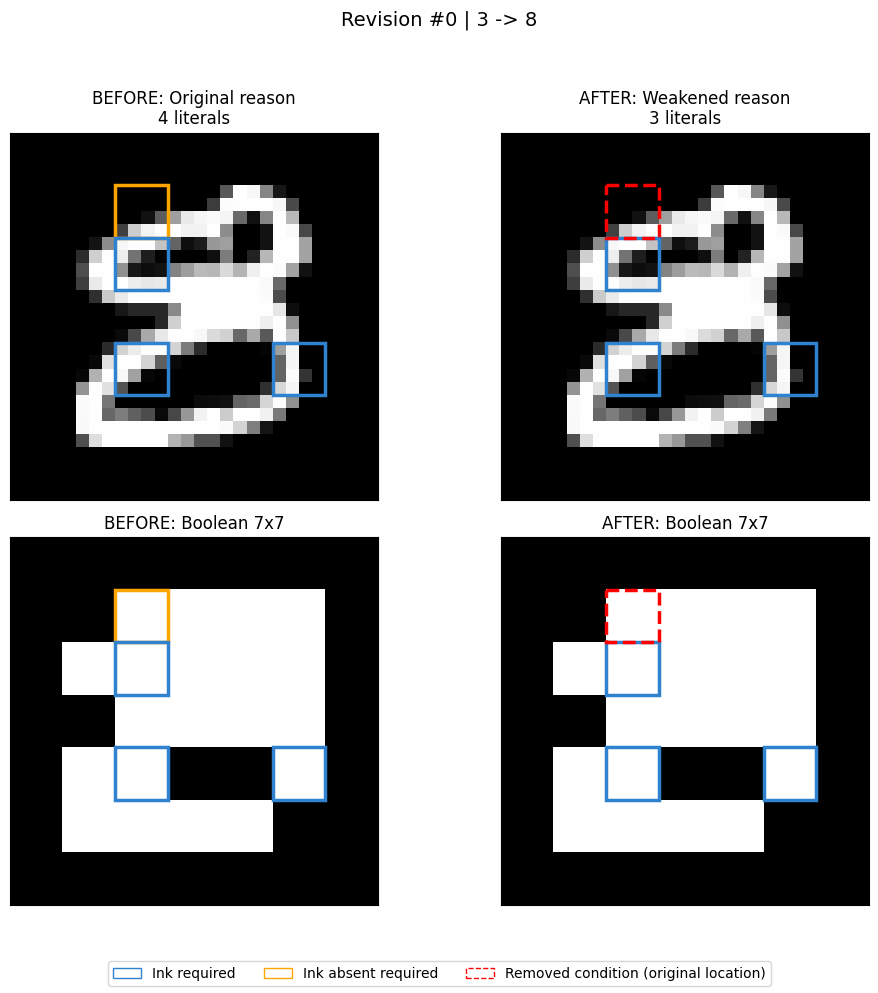

Original: ¬ink_r1_c2 ∧ ink_r2_c2 ∧ ink_r4_c2 ∧ ink_r4_c5
Removed: ¬ink_r1_c2
Revised: ink_r2_c2 ∧ ink_r4_c2 ∧ ink_r4_c5
Prediction: 3 -> 8


In [27]:
from matplotlib.patches import Rectangle, Patch
import numpy as np
import matplotlib.pyplot as plt

SOURCE_INDEX = 0

source = candidates.reasons[SOURCE_INDEX]

revision_preview = apply_minimal_weakening( bdd, root, instance, source, desired_label=actual, require_minimum_disagreement=candidates.nearest_distance)

original = revision_preview.original_reason
weakened = revision_preview.weakened_reason
removed = revision_preview.removed_literals

grid = int(data["metadata"]["feature_spec"]["grid_size"])
image = np.asarray(data[f"{SPLIT}_images"][EXAMPLE_INDEX])
boolean_image = np.asarray(
    data[f"{SPLIT}_features"][EXAMPLE_INDEX]
).reshape(grid, grid)

def draw_reason(ax, pixels, reason, *, boolean=False, show_removed=False):
    resolution = grid if boolean else 28
    cell_size = resolution / grid
    ax.imshow( pixels, cmap="gray",  vmin=0, vmax=1 if boolean else 255, interpolation="nearest", )
    for feature, value in reason:
        r, c = divmod(int(feature), grid)
        color = "#3182CE" if value else "orange"
        ax.add_patch( Rectangle((c * cell_size - 0.5, r * cell_size - 0.5),cell_size, cell_size, fill=False, edgecolor=color,linewidth=2.5, ))
    if show_removed:
        for feature, value in removed:
            r, c = divmod(int(feature), grid)
            ax.add_patch( Rectangle( (c * cell_size - 0.5, r * cell_size - 0.5),cell_size, cell_size, fill=False, edgecolor="red", linewidth=2.5, linestyle="--",) )
    ax.set_xticks([])
    ax.set_yticks([])

fig, axes = plt.subplots(2, 2, figsize=(10, 10))
draw_reason(axes[0, 0], image, original)
draw_reason(axes[0, 1], image, weakened, show_removed=True)
draw_reason(axes[1, 0], boolean_image, original, boolean=True)
draw_reason(axes[1, 1], boolean_image, weakened,boolean=True, show_removed=True)

axes[0, 0].set_title(f"BEFORE: Original reason\n{len(original)} literals")
axes[0, 1].set_title(f"AFTER: Weakened reason\n{len(weakened)} literals")
axes[1, 0].set_title(f"BEFORE: Boolean {grid}x{grid}")
axes[1, 1].set_title(f"AFTER: Boolean {grid}x{grid}")

fig.legend(
    handles=[
        Patch(edgecolor="#3182CE", facecolor="none", label="Ink required"),
        Patch(edgecolor="orange", facecolor="none", label="Ink absent required"),
        Patch(
            edgecolor="red", facecolor="none",
            linestyle="--", label="Removed condition (original location)"
        ),
    ],
    loc="lower center",
    ncol=3,
)
fig.suptitle(f"Revision #{SOURCE_INDEX} | " f"{label_name(data, predicted)} -> {label_name(data, actual)}", fontsize=14,)
plt.tight_layout(rect=[0, 0.07, 1, 0.95])
plt.show()

print("Original:", term_text(original, ex.feature_names))
print("Removed:", term_text(removed, ex.feature_names))
print("Revised:", term_text(weakened, ex.feature_names))
print("Prediction:",label_name(data, revision_preview.target_label_before),"->", label_name(data, revision_preview.target_label_after))

##  SELECTING A REASON


- For a target changed from NO to YES: Δ′ = Δ ∨ ρ
- For a target changed from YES to NO: Δ′ = ¬(¬Δ ∨ ρ)

Original source reason: ¬ink_r1_c2 ∧ ink_r2_c2 ∧ ink_r4_c2 ∧ ink_r4_c5
Removed disagreeing literals: ¬ink_r1_c2
Weakened reason: ink_r2_c2 ∧ ink_r4_c2 ∧ ink_r4_c5
Target label before: 1 | after: 0
Existing desired-class region preserved (symbolic proof): True


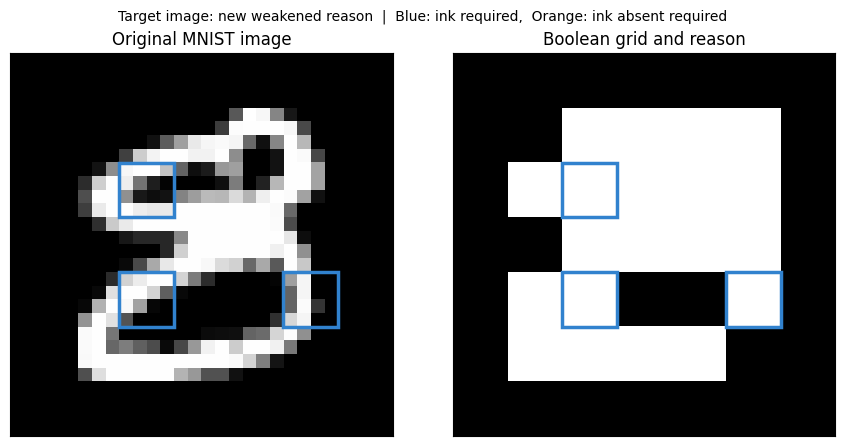

In [23]:
SOURCE_INDEX = 0 
revision = None
if candidates is None or candidates.nearest_distance is None or not candidates.reasons:
    print('No editable candidate currently available. Select a mistake or increase enumeration limits.')
else:
    source = candidates.reasons[SOURCE_INDEX]
    revision = apply_minimal_weakening(
        bdd, root, instance, source, desired_label=actual,
        require_minimum_disagreement=candidates.nearest_distance
    )
    print('Original source reason:', term_text(source, ex.feature_names))
    print('Removed disagreeing literals:', term_text(revision.removed_literals, ex.feature_names))
    print('Weakened reason:', term_text(revision.weakened_reason, ex.feature_names))
    print('Target label before:', revision.target_label_before, '| after:', revision.target_label_after)
    print('Existing desired-class region preserved (symbolic proof):',
          revision.preserved_old_target_class)
    fig = plot_instance_reason(data, split=SPLIT, index=EXAMPLE_INDEX,
                               term=revision.weakened_reason,
                               title='Target image: new weakened reason')
    plt.show()

## REVISION's EFFECT



In [24]:
if revision is not None:
    summary_rows = []
    for split_name in ('train', 'val'):
        stats = compare_predictions(bdd, root, revision.new_root,
                                    data[f'{split_name}_features'],
                                    data[f'{split_name}_labels'])
        summary_rows.append({'split': split_name, **stats})
    display(pd.DataFrame(summary_rows))

,split,n,changed,changed_fraction,negative_to_positive,positive_to_negative,accuracy_before,accuracy_after,corrected_errors,new_errors
0,train,1600,36,0.0225,0,36,0.9225,0.9125,10,26
1,val,400,7,0.0175,0,7,0.9075,0.9000,2,5


## EXPORT CLASSIFIER


In [13]:
if revision is not None:
    revision_out = repo_root / 'application_mnist' / 'revision' / 'outputs' / EXPERIMENT_NAME
    revision_out.mkdir(parents=True, exist_ok=True)
    patch_file = export_revision(bdd, revision,
                                 revision_out / f'{SPLIT}_{EXAMPLE_INDEX}_source_{SOURCE_INDEX}.json',
                                 ex.feature_names)
    restored_bdd, restored_root, metadata = load_revision(patch_file)
    assert restored_bdd.evaluate(restored_root, instance) == (actual == 1)
    print('Saved:', patch_file)


Saved: C:\Users\sofia\OneDrive\Desktop\Research\Code\ClassifierRevisionHumanFeedback\application_mnist\revision\outputs\3_vs_8_g7_t20_seed42\val_9_source_0.json


In [14]:
RUN_FINAL_TEST = True
if RUN_FINAL_TEST and revision is not None:
    stats = compare_predictions(bdd, root, revision.new_root,
                                data['test_features'], data['test_labels'])
    display(pd.DataFrame([{'split': 'test', **stats}]))
else:
    print('Test set not evaluated for the revision.')

,split,n,changed,changed_fraction,negative_to_positive,positive_to_negative,accuracy_before,accuracy_after,corrected_errors,new_errors
0,test,400,12,0.03,0,12,0.9075,0.9075,6,6
